# AMR Prediction: Random Forest Baseline

## 1. Objective

This experiment evaluates a conventional machine learning approach for predicting ciprofloxacin resistance in *Staphylococcus aureus* using whole-genome sequence data.

Genome sequences are converted into normalized k-mer frequency representations, which are subsequently used to train a Random Forest classifier.

This experiment serves as the conventional machine learning baseline for comparison with the pretrained DNABERT-2 representation approach.

## 2. Experimental Configuration

- Organism: Staphylococcus aureus
- Taxon ID: 1280
- Antibiotic: Ciprofloxacin
- Genome samples: 1,138
- Feature extraction: Normalized 5-mer frequencies
- Feature dimensions: 1,024
- Classifier: Random Forest
- Number of estimators: 300
- Class balancing: Balanced subsampling
- Random state: 42

## 3. Dataset Splitting

The dataset is divided into training, validation, and test sets using stratified genome-level splitting.

The same genome assignments and random state are used in the DNABERT-2 experiment to enable a fair comparison.

- Training: 70%
- Validation: 15%
- Testing: 15%

### 1. Loading the Local Genome Dataset

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate project root automatically
ROOT = Path.cwd()

while not (
    ROOT / "data" / "processed" / "ciprofloxacin_genome_level.csv"
).exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not locate AMR project directory.")
    ROOT = ROOT.parent

PROCESSED_DIR = ROOT / "data" / "processed"
GENOME_DIR = ROOT / "data" / "genomes"
FEATURE_DIR = PROCESSED_DIR / "kmer_features"

# Load labels
labels = pd.read_csv(
    PROCESSED_DIR / "ciprofloxacin_genome_level.csv"
)

# Match FASTA files to genome IDs
fasta_by_id = {
    path.stem: path
    for path in GENOME_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".fna", ".fasta", ".fa", ".fas"}
}

labels["Genome ID"] = labels["Genome ID"].astype(str)

cohort = labels[
    labels["Genome ID"].isin(fasta_by_id)
].copy()

cohort["FASTA Path"] = cohort["Genome ID"].map(fasta_by_id)

print("Project root:", ROOT)
print("Eligible genomes:", len(cohort))
print("\nClass distribution:")
print(cohort["Label"].value_counts().sort_index())

print("\nSaved feature directory exists:", FEATURE_DIR.exists())
print("Saved feature files:", 
      [p.name for p in FEATURE_DIR.glob("*.csv")])

Project root: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN
Eligible genomes: 1138

Class distribution:
Label
0    664
1    474
Name: count, dtype: int64

Saved feature directory exists: True
Saved feature files: ['test_5mer_features.csv', 'train_5mer_features.csv', 'validation_5mer_features.csv']


### 2. Reconstructing the DNABERT-2 Genome-Level Data Split

In [4]:
from sklearn.model_selection import train_test_split
import pandas as pd

RANDOM_STATE = 42

# Preserve the original CSV ordering used during dataset preparation
cohort = cohort[["Genome ID", "Label"]].copy()
cohort["Genome ID"] = cohort["Genome ID"].astype(str)

# 70% training, 30% temporary
train_df, temp_df = train_test_split(
    cohort,
    test_size=0.30,
    stratify=cohort["Label"],
    random_state=RANDOM_STATE
)

# Split temporary data equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Label"],
    random_state=RANDOM_STATE
)

# Save assignments
genome_splits = pd.concat([
    train_df.assign(Split="train"),
    val_df.assign(Split="validation"),
    test_df.assign(Split="test")
], ignore_index=True)

split_path = PROCESSED_DIR / "dnabert2_genome_splits.csv"
genome_splits.to_csv(split_path, index=False)

print("Training:", len(train_df))
print(train_df["Label"].value_counts().sort_index())

print("\nValidation:", len(val_df))
print(val_df["Label"].value_counts().sort_index())

print("\nTest:", len(test_df))
print(test_df["Label"].value_counts().sort_index())

print("\nSaved split:", split_path)

Training: 796
Label
0    464
1    332
Name: count, dtype: int64

Validation: 171
Label
0    100
1     71
Name: count, dtype: int64

Test: 171
Label
0    100
1     71
Name: count, dtype: int64

Saved split: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\data\processed\dnabert2_genome_splits.csv


### 3. Locating Previously Extracted 5-mer Feature Matrices

In [5]:
from pathlib import Path
import pandas as pd

# Search the project for previously generated feature matrices
root = Path.cwd()

feature_files = list(root.rglob("*5mer*features*.csv"))

print("Feature files found:", len(feature_files))

for file in feature_files:
    print(f"\nFile: {file}")
    df_temp = pd.read_csv(file, nrows=5)
    print("Columns:", df_temp.columns.tolist()[:8])
    print("Preview shape:", df_temp.shape)

Feature files found: 0


In [6]:
from pathlib import Path

cwd = Path.cwd()

print("Current working directory:", cwd)

for base in [cwd, cwd.parent, cwd.parent.parent]:
    print(f"\nSearching: {base}")

    for filename in [
        "train_5mer_features.csv",
        "validation_5mer_features.csv",
        "test_5mer_features.csv"
    ]:
        matches = list(base.rglob(filename))
        for match in matches:
            print("FOUND:", match)

Current working directory: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\notebooks

Searching: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\notebooks

Searching: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN
FOUND: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\data\processed\kmer_features\train_5mer_features.csv
FOUND: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\data\processed\kmer_features\validation_5mer_features.csv
FOUND: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\data\processed\kmer_features\test_5mer_features.csv

Searching: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine
FOUND: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\data\processed\kmer_features\train_5mer_features.csv
FOUND: d:\4th Year 7th Sem\AI and Systems Biolog

### 4. Inspecting Saved 5-mer Feature Matrices

In [7]:
import pandas as pd
from pathlib import Path

FEATURE_DIR = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "kmer_features"
)

feature_paths = {
    "train": FEATURE_DIR / "train_5mer_features.csv",
    "validation": FEATURE_DIR / "validation_5mer_features.csv",
    "test": FEATURE_DIR / "test_5mer_features.csv"
}

for name, path in feature_paths.items():
    df = pd.read_csv(path)

    print(f"\n{'='*45}")
    print(f"{name.upper()} FEATURES")
    print("Shape:", df.shape)
    print("First 10 columns:", df.columns[:10].tolist())
    print("Last 5 columns:", df.columns[-5:].tolist())
    print("First 3 rows:")
    display(df.head(3))


TRAIN FEATURES
Shape: (796, 1025)
First 10 columns: ['Genome ID', 'AAAAA', 'AAAAC', 'AAAAG', 'AAAAT', 'AAACA', 'AAACC', 'AAACG', 'AAACT', 'AAAGA']
Last 5 columns: ['TTTGT', 'TTTTA', 'TTTTC', 'TTTTG', 'TTTTT']
First 3 rows:


,Genome ID,AAAAA,AAAAC,AAAAG,AAAAT,AAACA,AAACC,AAACG,AAACT,AAAGA,...,TTTCG,TTTCT,TTTGA,TTTGC,TTTGG,TTTGT,TTTTA,TTTTC,TTTTG,TTTTT
0,1280.59769,0.004985,0.002136,0.002706,0.005263,0.002373,0.001093,0.001203,0.001562,0.002614,...,0.000935,0.002498,0.002646,0.001392,0.001224,0.002531,0.004955,0.002825,0.002655,0.005130
1,1280.88440,0.005181,0.002275,0.002805,0.005414,0.002615,0.001145,0.001263,0.001666,0.002810,...,0.000874,0.002439,0.002576,0.001287,0.001138,0.002323,0.004813,0.002793,0.002535,0.004968
2,1280.59527,0.004569,0.002087,0.002447,0.005089,0.002407,0.001107,0.001225,0.001595,0.002362,...,0.000979,0.002648,0.002566,0.001370,0.001147,0.002516,0.005035,0.003086,0.002621,0.005384



VALIDATION FEATURES
Shape: (171, 1025)
First 10 columns: ['Genome ID', 'AAAAA', 'AAAAC', 'AAAAG', 'AAAAT', 'AAACA', 'AAACC', 'AAACG', 'AAACT', 'AAAGA']
Last 5 columns: ['TTTGT', 'TTTTA', 'TTTTC', 'TTTTG', 'TTTTT']
First 3 rows:


,Genome ID,AAAAA,AAAAC,AAAAG,AAAAT,AAACA,AAACC,AAACG,AAACT,AAAGA,...,TTTCG,TTTCT,TTTGA,TTTGC,TTTGG,TTTGT,TTTTA,TTTTC,TTTTG,TTTTT
0,1280.26026,0.005059,0.002154,0.002856,0.005272,0.002453,0.001050,0.001236,0.001517,0.002809,...,0.000924,0.002274,0.002664,0.001314,0.001213,0.002499,0.004846,0.002574,0.002592,0.004778
1,1280.59269,0.005276,0.002188,0.003002,0.005408,0.002577,0.001038,0.001255,0.001585,0.003026,...,0.000890,0.002204,0.002659,0.001299,0.001210,0.002374,0.004839,0.002514,0.002570,0.004803
2,1280.59738,0.004877,0.002151,0.002635,0.005245,0.002472,0.001101,0.001223,0.001598,0.002549,...,0.000933,0.002544,0.002611,0.001347,0.001143,0.002427,0.004970,0.002940,0.002589,0.005230



TEST FEATURES
Shape: (171, 1025)
First 10 columns: ['Genome ID', 'AAAAA', 'AAAAC', 'AAAAG', 'AAAAT', 'AAACA', 'AAACC', 'AAACG', 'AAACT', 'AAAGA']
Last 5 columns: ['TTTGT', 'TTTTA', 'TTTTC', 'TTTTG', 'TTTTT']
First 3 rows:


,Genome ID,AAAAA,AAAAC,AAAAG,AAAAT,AAACA,AAACC,AAACG,AAACT,AAAGA,...,TTTCG,TTTCT,TTTGA,TTTGC,TTTGG,TTTGT,TTTTA,TTTTC,TTTTG,TTTTT
0,1280.51882,0.004941,0.002164,0.002739,0.005277,0.002452,0.001087,0.001219,0.001625,0.002753,...,0.000955,0.002410,0.002623,0.001346,0.001194,0.002497,0.004909,0.002757,0.002606,0.005040
1,1280.59374,0.005066,0.002195,0.002781,0.005284,0.002515,0.001083,0.001250,0.001567,0.002763,...,0.000946,0.002397,0.002623,0.001324,0.001197,0.002476,0.004865,0.002763,0.002596,0.004982
2,1280.73750,0.005433,0.002258,0.003053,0.005510,0.002642,0.001064,0.001273,0.001595,0.003024,...,0.000819,0.002209,0.002586,0.001252,0.001211,0.002299,0.004817,0.002497,0.002471,0.004762


### 5. Combining 5-mer Features and Aligning Genome-Level Splits

In [8]:
# Load all three previously extracted feature matrices
feature_dfs = {
    name: pd.read_csv(path)
    for name, path in feature_paths.items()
}

# Combine them into one genome-level feature matrix
X_all = pd.concat(feature_dfs.values(), ignore_index=True)

# Normalize genome IDs
X_all["Genome ID"] = X_all["Genome ID"].astype(str)

cohort["Genome ID"] = cohort["Genome ID"].astype(str)
genome_splits["Genome ID"] = genome_splits["Genome ID"].astype(str)

# Recover phenotype labels using the original dataset
label_map = cohort.set_index("Genome ID")["Label"]

X_all["Label"] = X_all["Genome ID"].map(label_map)

# Recover DNABERT-2 split assignments
split_map = genome_splits.set_index("Genome ID")["Split"]

X_all["Split"] = X_all["Genome ID"].map(split_map)

# Report alignment
print("Combined feature matrix:", X_all.shape)
print("Unique genomes:", X_all["Genome ID"].nunique())

print("\nMissing labels:", X_all["Label"].isna().sum())
print("Missing split assignments:", X_all["Split"].isna().sum())

print("\nSplit distribution:")
print(X_all["Split"].value_counts(dropna=False))

print("\nLabel distribution:")
print(X_all["Label"].value_counts(dropna=False))

print("\nFeature count:", X_all.shape[1] - 3)

Combined feature matrix: (1138, 1027)
Unique genomes: 1138

Missing labels: 0
Missing split assignments: 0

Split distribution:
Split
train         796
validation    171
test          171
Name: count, dtype: int64

Label distribution:
Label
0    664
1    474
Name: count, dtype: int64

Feature count: 1024


C:\Users\praja\AppData\Local\Temp\ipykernel_20948\1218228430.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_all["Label"] = X_all["Genome ID"].map(label_map)
C:\Users\praja\AppData\Local\Temp\ipykernel_20948\1218228430.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_all["Split"] = X_all["Genome ID"].map(split_map)


### 6. Training Random Forest on the Reconstructed Genome-Level Split

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np

# Separate feature matrix and labels
feature_columns = [
    col for col in X_all.columns
    if col not in ["Genome ID", "Label", "Split"]
]

# Create train, validation and test datasets
train_data = X_all[X_all["Split"] == "train"]
val_data = X_all[X_all["Split"] == "validation"]
test_data = X_all[X_all["Split"] == "test"]

X_train = train_data[feature_columns]
y_train = train_data["Label"].astype(int)

X_val = val_data[feature_columns]
y_val = val_data["Label"].astype(int)

X_test = test_data[feature_columns]
y_test = test_data["Label"].astype(int)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Generate probabilities
val_probabilities = rf_model.predict_proba(X_val)[:, 1]
test_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest training complete!")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))
print("Feature count:", X_train.shape[1])

print("\nValidation ROC-AUC:", round(
    roc_auc_score(y_val, val_probabilities), 4
))

print("Validation PR-AUC:", round(
    average_precision_score(y_val, val_probabilities), 4
))

Random Forest training complete!
Training samples: 796
Validation samples: 171
Test samples: 171
Feature count: 1024

Validation ROC-AUC: 0.8796
Validation PR-AUC: 0.8641


### 7. Validation-Based Classification Threshold Selection

In [10]:
from sklearn.metrics import balanced_accuracy_score
import numpy as np

thresholds = np.arange(0.01, 1.00, 0.001)

validation_scores = [
    balanced_accuracy_score(
        y_val,
        (val_probabilities >= threshold).astype(int)
    )
    for threshold in thresholds
]

best_index = np.argmax(validation_scores)
best_threshold = thresholds[best_index]

val_predictions = (
    val_probabilities >= best_threshold
).astype(int)

print("Selected threshold:", round(best_threshold, 4))
print("Validation balanced accuracy:",
      round(validation_scores[best_index], 4))

print("\nValidation confusion matrix:")
print(confusion_matrix(y_val, val_predictions))

Selected threshold: 0.404
Validation balanced accuracy: 0.8094

Validation confusion matrix:
[[83 17]
 [15 56]]


### 8. Random Forest Evaluation on the Held-Out Test Set

In [11]:
# Apply the validation-selected threshold to the test set
rf_test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Calculate test metrics
rf_test_metrics = {
    "Accuracy": np.mean(rf_test_predictions == y_test),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test, rf_test_predictions
    ),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities),
    "Precision": precision_score(y_test, rf_test_predictions),
    "Recall": recall_score(y_test, rf_test_predictions),
    "F1-score": f1_score(y_test, rf_test_predictions)
}

print("RANDOM FOREST — TEST RESULTS")
print("=" * 40)
print("Threshold:", round(best_threshold, 4))

for metric, value in rf_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_predictions))

RANDOM FOREST — TEST RESULTS
Threshold: 0.404
Accuracy: 0.8538
Balanced Accuracy: 0.8423
ROC-AUC: 0.9046
PR-AUC: 0.8950
Precision: 0.8594
Recall: 0.7746
F1-score: 0.8148

Confusion Matrix:
[[91  9]
 [16 55]]


### 9. Comparative Evaluation of Random Forest and DNABERT-2

,Metric,Random Forest,DNABERT-2
0,Accuracy,0.8538,0.8947
1,Balanced Accuracy,0.8423,0.8855
2,ROC-AUC,0.9046,0.9289
3,PR-AUC,0.8950,0.9192
4,Precision,0.8594,0.9077
5,Recall,0.7746,0.8310
6,F1-score,0.8148,0.8676


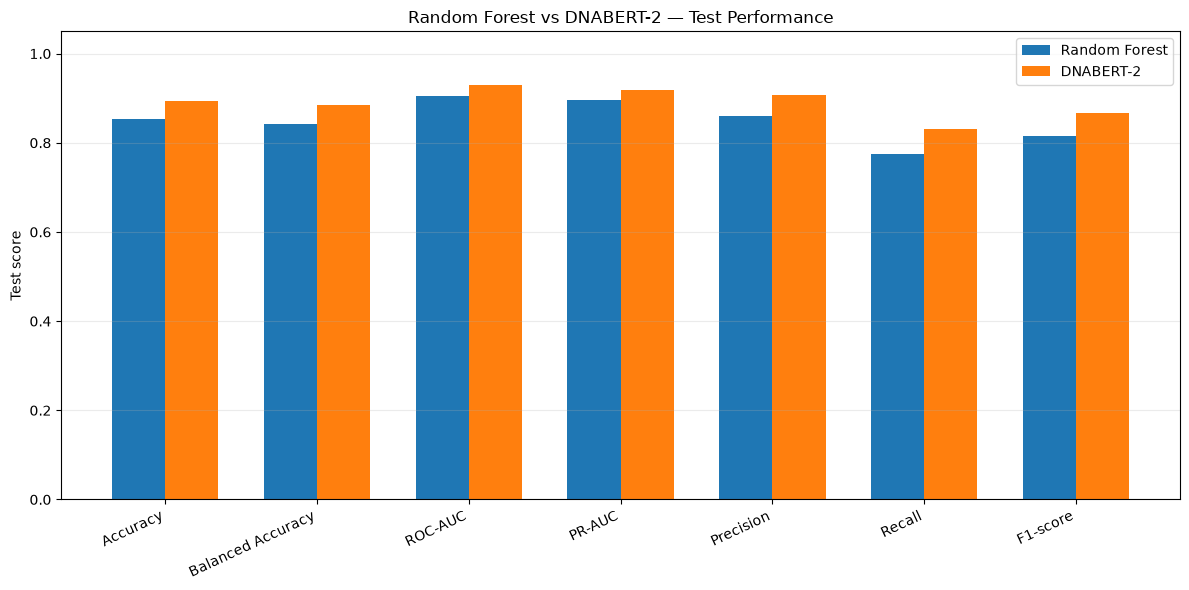

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy", "Balanced Accuracy", "ROC-AUC",
        "PR-AUC", "Precision", "Recall", "F1-score"
    ],
    "Random Forest": [
        0.8538, 0.8423, 0.9046, 0.8950,
        0.8594, 0.7746, 0.8148
    ],
    "DNABERT-2": [
        0.8947, 0.8855, 0.9289, 0.9192,
        0.9077, 0.8310, 0.8676
    ]
})

display(comparison.round(4))

# Grouped comparison chart
x = np.arange(len(comparison["Metric"]))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    comparison["Random Forest"],
    width,
    label="Random Forest"
)

plt.bar(
    x + width/2,
    comparison["DNABERT-2"],
    width,
    label="DNABERT-2"
)

plt.xticks(x, comparison["Metric"], rotation=25, ha="right")
plt.ylabel("Test score")
plt.ylim(0, 1.05)
plt.title("Random Forest vs DNABERT-2 — Test Performance")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 10. Exporting Model Comparison Results

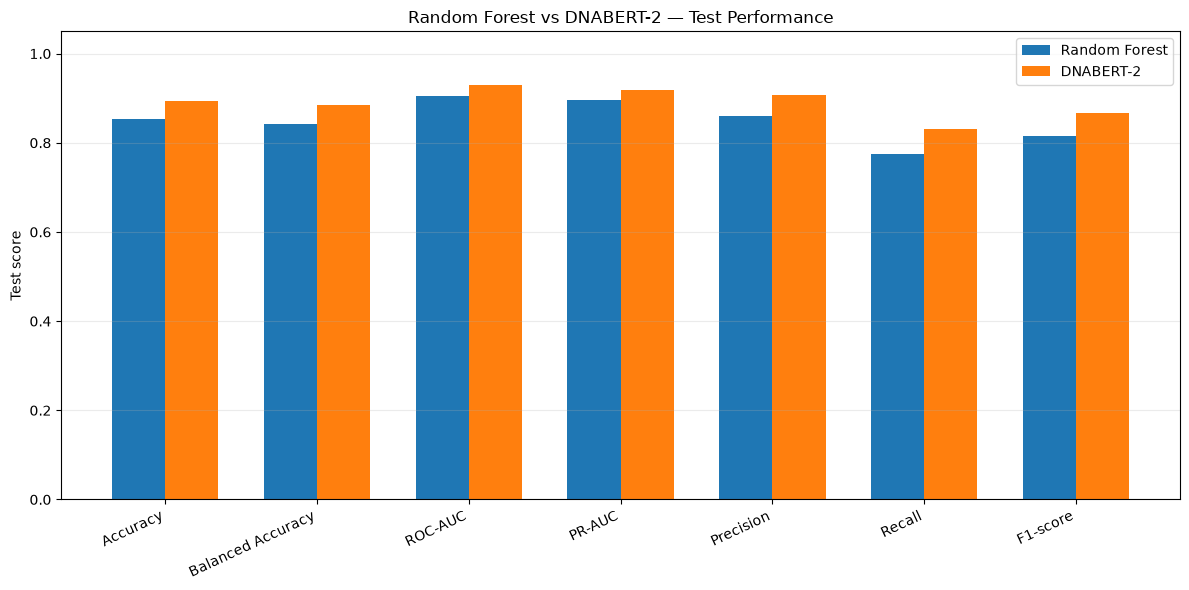

Comparison artifacts saved:
d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\results\model_comparison
CSV and 300-DPI PNG generated successfully.


In [13]:
from pathlib import Path

# Create results directory
PROJECT_ROOT = Path.cwd().parent
RESULTS_DIR = PROJECT_ROOT / "results" / "model_comparison"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison table
comparison.to_csv(
    RESULTS_DIR / "random_forest_vs_dnabert2.csv",
    index=False
)

# Save publication-quality graph
plt.figure(figsize=(12, 6))

x = np.arange(len(comparison["Metric"]))
width = 0.35

plt.bar(x - width/2, comparison["Random Forest"], width,
        label="Random Forest")
plt.bar(x + width/2, comparison["DNABERT-2"], width,
        label="DNABERT-2")

plt.xticks(x, comparison["Metric"], rotation=25, ha="right")
plt.ylabel("Test score")
plt.ylim(0, 1.05)
plt.title("Random Forest vs DNABERT-2 — Test Performance")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "random_forest_vs_dnabert2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison artifacts saved:")
print(RESULTS_DIR)
print("CSV and 300-DPI PNG generated successfully.")

### 11. Verifying Genome-Level Split Consistency

In [14]:
from pathlib import Path
import pandas as pd

# Locate the project directories
PROJECT_ROOT = Path.cwd().parent
FEATURE_DIR = PROJECT_ROOT / "data" / "processed" / "kmer_features"
SPLIT_FILE = PROJECT_ROOT / "data" / "processed" / "dnabert2_genome_splits.csv"

# Original Random Forest genome assignments
original_splits = {
    "train": pd.read_csv(FEATURE_DIR / "train_5mer_features.csv")["Genome ID"].astype(str),
    "validation": pd.read_csv(FEATURE_DIR / "validation_5mer_features.csv")["Genome ID"].astype(str),
    "test": pd.read_csv(FEATURE_DIR / "test_5mer_features.csv")["Genome ID"].astype(str)
}

# DNABERT-2 experiment assignments
dnabert_splits = pd.read_csv(SPLIT_FILE)
print("DNABERT-2 split columns:", dnabert_splits.columns.tolist())

# Normalize split names and genome IDs
dnabert_splits["Genome ID"] = dnabert_splits["Genome ID"].astype(str)
dnabert_splits["Split"] = dnabert_splits["Split"].astype(str).str.lower()

# Compare each split
for split in ["train", "validation", "test"]:
    original_ids = set(original_splits[split])
    dnabert_ids = set(
        dnabert_splits.loc[
            dnabert_splits["Split"] == split, "Genome ID"
        ]
    )

    print(f"\n{split.upper()}")
    print("Original RF genomes:", len(original_ids))
    print("DNABERT-2 genomes:", len(dnabert_ids))
    print("Shared genomes:", len(original_ids & dnabert_ids))
    print("Only in original RF:", len(original_ids - dnabert_ids))
    print("Only in DNABERT-2:", len(dnabert_ids - original_ids))
    print("Identical assignments:", original_ids == dnabert_ids)

DNABERT-2 split columns: ['Genome ID', 'Label', 'Split']

TRAIN
Original RF genomes: 796
DNABERT-2 genomes: 796
Shared genomes: 796
Only in original RF: 0
Only in DNABERT-2: 0
Identical assignments: True

VALIDATION
Original RF genomes: 171
DNABERT-2 genomes: 171
Shared genomes: 171
Only in original RF: 0
Only in DNABERT-2: 0
Identical assignments: True

TEST
Original RF genomes: 171
DNABERT-2 genomes: 171
Shared genomes: 171
Only in original RF: 0
Only in DNABERT-2: 0
Identical assignments: True


### Split Consistency Verification

The original Random Forest and DNABERT-2 experiments were verified to use identical genome-level training, validation, and test assignments.

- Training: 796 identical genomes
- Validation: 171 identical genomes
- Testing: 171 identical genomes

This ensures a consistent evaluation basis for comparing model performance.

In [15]:
import json
from pathlib import Path

notebook_path = Path.cwd() / "amr_kmer_randomforest.ipynb"

if not notebook_path.exists():
    notebook_path = Path.cwd().parent / "amr_kmer_randomforest.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    original_nb = json.load(f)

keywords = [
    "RandomForestClassifier",
    "best_threshold",
    "balanced_accuracy",
    "roc_auc",
    "confusion_matrix",
    "n_estimators"
]

for i, cell in enumerate(original_nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(word in source for word in keywords):
        print(f"\n{'='*65}")
        print(f"CELL {i}")
        print(source[:5000])

        for output in cell.get("outputs", []):
            if "text" in output:
                print("OUTPUT:")
                print("".join(output["text"])[:2500])


CELL 1

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

RANDOM_STATE = 42
K = 5

print("Imports successful.")
print("Working directory:", Path.cwd())

OUTPUT:
Imports successful.
Working directory: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\notebooks


CELL 12

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import numpy as np
import time

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
   

In [16]:
# Train Random Forest using the original project configuration

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")
print("Training samples:", len(X_train))
print("Number of features:", X_train.shape[1])

Random Forest training completed.
Training samples: 796
Number of features: 1024


## Recalculate validation probabilities and select the threshold

In [17]:
# Generate validation probabilities
val_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Search for the threshold with the highest validation balanced accuracy
thresholds = np.arange(0.01, 1.00, 0.001)

validation_scores = [
    balanced_accuracy_score(
        y_val,
        (val_probabilities >= threshold).astype(int)
    )
    for threshold in thresholds
]

best_index = np.argmax(validation_scores)
best_threshold = thresholds[best_index]
best_val_balanced_accuracy = validation_scores[best_index]

print("Optimal threshold:", round(best_threshold, 3))
print("Validation balanced accuracy:", round(best_val_balanced_accuracy, 4))

Optimal threshold: 0.393
Validation balanced accuracy: 0.8055


In [19]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Metrics imported successfully.")

Metrics imported successfully.


In [20]:
# Evaluate Random Forest on the independent test set

test_probabilities = rf_model.predict_proba(X_test)[:, 1]

y_test_pred = (test_probabilities >= best_threshold).astype(int)

print("Random Forest — Test Set Results")
print("--------------------------------")
print("Threshold:", round(best_threshold, 3))
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_probabilities), 4))
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1-score:", round(f1_score(y_test, y_test_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Susceptible", "Resistant"]
))

Random Forest — Test Set Results
--------------------------------
Threshold: 0.393
Accuracy: 0.848
Balanced Accuracy: 0.8435
ROC-AUC: 0.9097
PR-AUC: 0.9061
Precision: 0.8169
Recall: 0.8169
F1-score: 0.8169

Confusion Matrix:
[[87 13]
 [13 58]]

Classification Report:
              precision    recall  f1-score   support

 Susceptible       0.87      0.87      0.87       100
   Resistant       0.82      0.82      0.82        71

    accuracy                           0.85       171
   macro avg       0.84      0.84      0.84       171
weighted avg       0.85      0.85      0.85       171



FINAL MODEL COMPARISON — TEST SET


,Metric,Random Forest,DNABERT-2
0,Accuracy,0.8480,0.8947
1,Balanced Accuracy,0.8435,0.8855
2,ROC-AUC,0.9097,0.9289
3,PR-AUC,0.9061,0.9192
4,Precision,0.8169,0.9077
5,Recall,0.8169,0.8310
6,F1-score,0.8169,0.8676


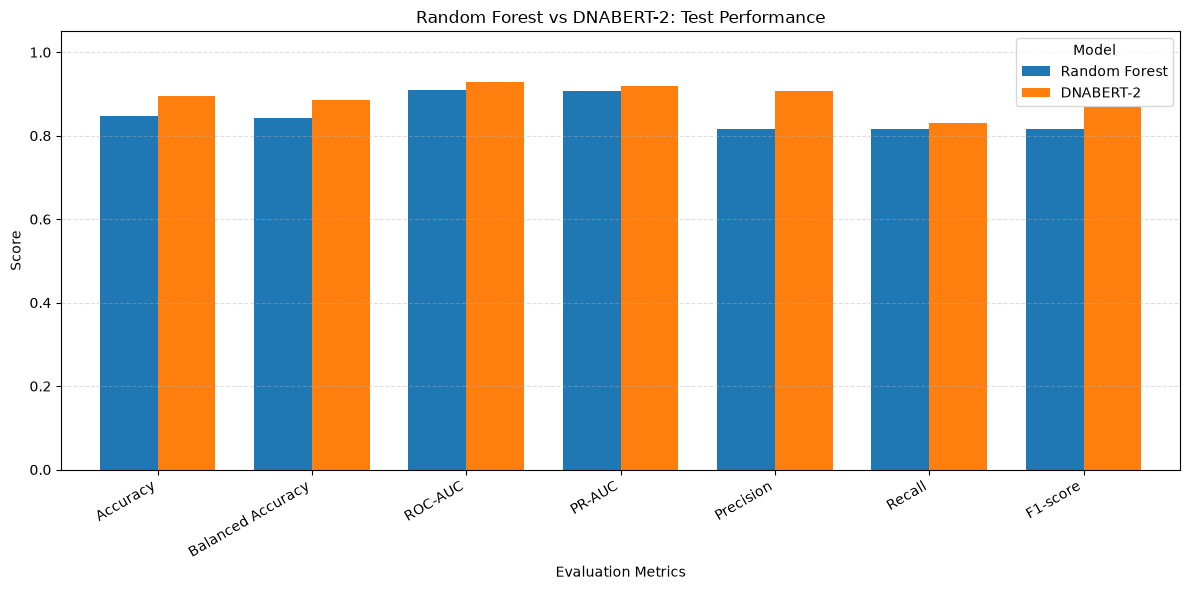

Comparison table and chart saved successfully.


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Final test-set metrics for both models
comparison_data = {
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Random Forest": [
        0.8480,
        0.8435,
        0.9097,
        0.9061,
        0.8169,
        0.8169,
        0.8169
    ],
    "DNABERT-2": [
        0.8947,
        0.8855,
        0.9289,
        0.9192,
        0.9077,
        0.8310,
        0.8676
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("FINAL MODEL COMPARISON — TEST SET")
display(comparison_df.round(4))

# Save comparison table
output_dir = Path("results/model_comparison")
output_dir.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    output_dir / "final_model_comparison.csv",
    index=False
)

# Generate grouped bar chart
plot_df = comparison_df.set_index("Metric")

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title("Random Forest vs DNABERT-2: Test Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylim(0, 1.05)
ax.legend(title="Model")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    output_dir / "final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison table and chart saved successfully.")

,Metric,Random Forest,DNABERT-2,CNN + Attention-MIL
0,Accuracy,0.8480,0.8947,0.5848
1,Balanced Accuracy,0.8435,0.8855,0.5000
2,ROC-AUC,0.9097,0.9289,0.6246
3,PR-AUC,0.9061,0.9192,0.5195
4,Precision,0.8169,0.9077,0.0000
5,Recall,0.8169,0.8310,0.0000
6,F1-score,0.8169,0.8676,0.0000


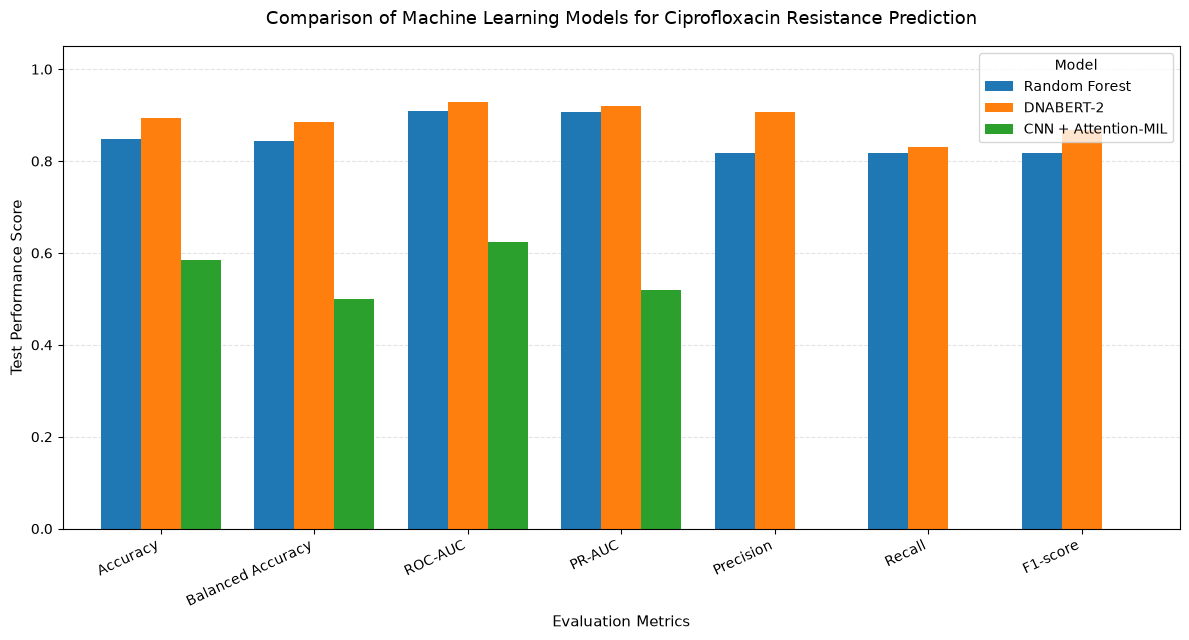

Three-model comparison saved successfully.


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# Three-model test performance comparison
comparison_3models = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Random Forest": [
        0.8480, 0.8435, 0.9097, 0.9061,
        0.8169, 0.8169, 0.8169
    ],
    "DNABERT-2": [
        0.8947, 0.8855, 0.9289, 0.9192,
        0.9077, 0.8310, 0.8676
    ],
    "CNN + Attention-MIL": [
    0.5848,
    0.5000,
    0.6246,
    0.5195,
    0.0000,
    0.0000,
    0.0000
]
})

# Display comparison table
display(comparison_3models.round(4))

# Plot
plot_df = comparison_3models.set_index("Metric")

fig, ax = plt.subplots(figsize=(12, 6.5))

plot_df.plot(
    kind="bar",
    ax=ax,
    width=0.78
)

ax.set_title(
    "Comparison of Machine Learning Models for Ciprofloxacin Resistance Prediction",
    fontsize=13,
    pad=16
)

ax.set_ylabel("Test Performance Score", fontsize=11)
ax.set_xlabel("Evaluation Metrics", fontsize=11)
ax.set_ylim(0, 1.05)

ax.set_xticklabels(
    plot_df.index,
    rotation=25,
    ha="right"
)

ax.legend(
    title="Model",
    loc="upper right",
    frameon=True
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()

# Save publication-quality figure
output_dir = Path("results/model_comparison")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "three_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    output_dir / "three_model_comparison.pdf",
    bbox_inches="tight"
)

comparison_3models.to_csv(
    output_dir / "three_model_comparison.csv",
    index=False
)

plt.show()

print("Three-model comparison saved successfully.")

In [26]:
import pandas as pd

# Random Forest – Test Set Performance

rf_results = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "ROC-AUC",
        "PR-AUC",
        "Resistant Precision",
        "Resistant Recall",
        "Resistant F1-score"
    ],
    "Score": [
        0.8480,
        0.8435,
        0.9097,
        0.9061,
        0.8169,
        0.8169,
        0.8169
    ]
})

print("RANDOM FOREST MODEL – TEST SET PERFORMANCE")
display(rf_results)

RANDOM FOREST MODEL – TEST SET PERFORMANCE


,Evaluation Metric,Score
0,Accuracy,0.8480
1,Balanced Accuracy,0.8435
2,ROC-AUC,0.9097
3,PR-AUC,0.9061
4,Resistant Precision,0.8169
5,Resistant Recall,0.8169
6,Resistant F1-score,0.8169


## Random Forest Confusion Matrix

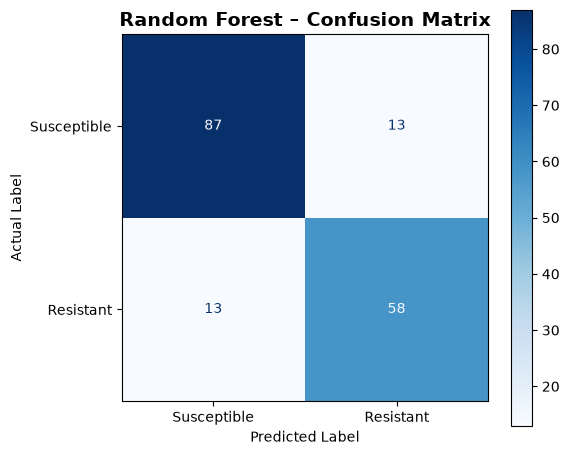

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use the validation-selected threshold
threshold = 0.393

y_pred_rf = (rf_model.predict_proba(X_test)[:, 1] >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Susceptible", "Resistant"]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")

ax.set_title("Random Forest – Confusion Matrix", fontsize=14, fontweight="bold")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

## RANDOM FORESR CLASSIFICATION REPORT

In [29]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_test,
    y_pred_rf,
    target_names=["Susceptible", "Resistant"],
    output_dict=True
)

rf_report = pd.DataFrame(report).T.loc[
    ["Susceptible", "Resistant"],
    ["precision", "recall", "f1-score"]
].round(4)

print("RANDOM FOREST – CLASSIFICATION REPORT")
display(rf_report)

RANDOM FOREST – CLASSIFICATION REPORT


,precision,recall,f1-score
Susceptible,0.8700,0.8700,0.8700
Resistant,0.8169,0.8169,0.8169


## DNABERT2 test set performance metrics

In [30]:
import pandas as pd

# DNABERT-2 – Test Set Performance

dnabert_results = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "ROC-AUC",
        "PR-AUC",
        "Resistant Precision",
        "Resistant Recall",
        "Resistant F1-score"
    ],
    "Score": [
        0.8947,
        0.8855,
        0.9289,
        0.9192,
        0.9077,
        0.8310,
        0.8676
    ]
})

print("DNABERT-2 MODEL – TEST SET PERFORMANCE")
display(dnabert_results)

DNABERT-2 MODEL – TEST SET PERFORMANCE


,Evaluation Metric,Score
0,Accuracy,0.8947
1,Balanced Accuracy,0.8855
2,ROC-AUC,0.9289
3,PR-AUC,0.9192
4,Resistant Precision,0.9077
5,Resistant Recall,0.8310
6,Resistant F1-score,0.8676


## CNN + Attention-MIL – Test Set Performance metrics

In [31]:
import pandas as pd

# CNN + Attention-MIL – Test Set Performance

cnn_results = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "ROC-AUC",
        "PR-AUC",
        "Resistant Precision",
        "Resistant Recall",
        "Resistant F1-score"
    ],
    "Score": [
        0.5848,
        0.5000,
        0.6246,
        0.5195,
        0.0000,
        0.0000,
        0.0000
    ]
})

print("CNN + ATTENTION-MIL MODEL – TEST SET PERFORMANCE")
display(cnn_results)

CNN + ATTENTION-MIL MODEL – TEST SET PERFORMANCE


,Evaluation Metric,Score
0,Accuracy,0.5848
1,Balanced Accuracy,0.5000
2,ROC-AUC,0.6246
3,PR-AUC,0.5195
4,Resistant Precision,0.0000
5,Resistant Recall,0.0000
6,Resistant F1-score,0.0000


## DNABERT CONFUSION MATRIX

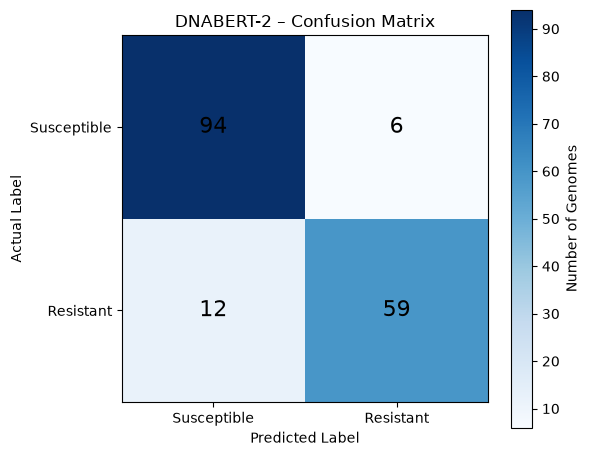

In [34]:
import matplotlib.pyplot as plt
import numpy as np

cm = np.array([
    [94, 6],
    [12, 59]
])

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Susceptible", "Resistant"])
ax.set_yticklabels(["Susceptible", "Resistant"])

ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
ax.set_title("DNABERT-2 – Confusion Matrix")

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16)

plt.colorbar(im, ax=ax, label="Number of Genomes")
plt.tight_layout()
plt.show()

In [35]:
import pandas as pd

# DNABERT-2 – Classification Report

dnabert_report = pd.DataFrame({
    "Precision": [0.8868, 0.9077],
    "Recall": [0.9400, 0.8310],
    "F1-score": [0.9126, 0.8676]
}, index=["Susceptible", "Resistant"])

print("DNABERT-2 – CLASSIFICATION REPORT")
display(dnabert_report)

DNABERT-2 – CLASSIFICATION REPORT


,Precision,Recall,F1-score
Susceptible,0.8868,0.940,0.9126
Resistant,0.9077,0.831,0.8676
